# Predicting Formula 1 race lap times: Linear Regression vs Random Forest Regression
### A fully worked mini-project on the 2023 Italian Grand Prix (FastF1 data) – IN3300/INM431 Machine Learning

**Problem.** In a race, a strategist needs to know how fast a car *will* lap given its tyres, fuel load and situation on track. A good lap-time model is the core of tyre-degradation and pit-stop decisions. FastF1 gives a record for every lap of every car, so we can learn that model from data.

**Research question.** Given only information known *before* a lap is driven (tyre age, compound, race lap / fuel load, team, running position, gap to the car ahead), can we predict the lap time, and is a **Random Forest Regressor** more accurate than **Multiple Linear Regression**?

**Why these two methods?**
* *Linear Regression* mirrors the additive lap-time model used in F1 race simulation (Heilmeier et al., 2020): lap time = base pace + tyre degradation(age, compound) + fuel effect + car/driver offsets. It is interpretable: every coefficient is "seconds per unit".
* *Random Forest* is a tree ensemble from the same family as XGBoost, which Todd et al. (2025, Imperial College & Mercedes-AMG F1) found to be the most accurate model for predicting tyre energy, ahead of linear regression and deep time-series models.

**Hypotheses.**
1. Both models will beat a naive baseline (always predicting the mean lap time) by a wide margin.
2. Following Todd et al. (2025), the tree ensemble (Random Forest) will have a lower test RMSE than Linear Regression on a random hold-out set.
3. Because trees cannot extrapolate, Linear Regression will be better at *forecasting* laps later in the race, where tyre ages exceed anything seen in training.

**How the references are used**

| # | Reference | Role in this project |
|---|---|---|
| [1] | Todd, Jiang, Russo, Winkler, Sale, McMillan & Rago (2025) *Explainable Time Series Prediction of Tyre Energy in Formula One Race Strategy*, ACM SAC '25 | **Benchmark**: Linear RMSE 7.916 vs XGBoost 4.785 (green-flag encoding), a 39.6 % reduction. We compare our *relative* improvement against this. |
| [2] | Nova SBE Work Project (2023) *From Data to Podium: Analytical Approaches to Understanding and Predicting Driver & Strategic Decisions in F1* | Precedent for building F1 datasets with FastF1 and for the strategy variables used (compound, pit timing, lap time, position); uses OLS regression and K-means. |
| [3] | de Faria & Ferreira (2024) *Podium and Influence: A Network Analysis of the Most Important F1 Drivers*, BraSNAM | Context only: a network (PageRank) study, not a predictive model, so it is **not** used as a benchmark. |
| [4] | Pereira, Ferreira & de Sousa (2026) *Residual Hybrid Learning for Data-Limited F1 Lap Time Prediction Across Multiple Circuits*, KDMiLe | Closest study: FastF1 lap-time prediction (including Monza) with a multiple-linear-regression baseline; inspires our hybrid extension. |
| [5] | Heilmeier, Graf, Betz & Lienkamp (2020) *Application of Monte Carlo Methods to Consider Probabilistic Effects in a Race Simulation for Circuit Motorsport*, Applied Sciences 10(12):4229 | Justifies the additive physical structure of the linear model. |

**Step-by-step plan:** (1) load data → (2) choose variables and rule out leakage → (3) clean → (4) engineer features → (5) explore with graphs → (6) train/test design → (7) tune Linear Regression → (8) tune Random Forest → (9) compare on the test set with significance tests → (10) diagnostics and feature importance → (11) critical test: forecasting the end of the race → (12) predict with the chosen model → (13) compare against the reference → (14) extension → (15) conclusions.


## 1. Setup
One colour per model is used in every chart (**blue = Linear Regression**, **orange = Random Forest**), and Pirelli's colours for the tyres (**yellow = Medium**, **grey = Hard**), so the figures can go straight onto the poster.

In [1]:
import warnings, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

FIG = Path("figures"); FIG.mkdir(exist_ok=True)
DATA = Path("data"); DATA.mkdir(exist_ok=True)

# One consistent visual language for every chart
LR_C, RF_C = "#2a78d6", "#eb6834"           # Linear Regression = blue, Random Forest = orange
COMP_C = {"MEDIUM": "#eda100", "HARD": "#52514e"}   # Pirelli: medium = yellow, hard = white/grey
INK, MUTED = "#0b0b0b", "#8a8984"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
    "axes.edgecolor": "#b5b4ae", "axes.labelcolor": INK, "axes.titleweight": "bold",
    "axes.titlesize": 11, "axes.labelsize": 10, "xtick.color": "#52514e", "ytick.color": "#52514e",
    "legend.frameon": False, "font.family": "DejaVu Sans", "lines.linewidth": 2,
})
SEED = 42
np.random.seed(SEED)

## 2. Loading the data with FastF1
`fastf1.get_session(year, event, "R")` returns a race session. `session.load()` downloads and processes several data sources. FastF1 offers much more than the lap table:

| FastF1 object | What it contains | Used here? |
|---|---|---|
| `session.laps` | One row per car per lap: lap/sector times, tyre compound & age, stint, pit in/out, track status, position, speed traps | **Yes – the main dataset** |
| `session.results` | Grid position, finishing position, status (finished/DNF), points | Context |
| `session.weather_data` | Air & track temperature, humidity, rainfall, wind (about one row per minute) | Not cached here – future work (one dry race has nearly constant weather) |
| `lap.get_car_data()` / `session.car_data` | Telemetry at ~4 Hz: Speed, RPM, Gear, Throttle, Brake, DRS | Not cached – future work (per-lap throttle/brake summaries, closest to Todd et al.'s inputs) |
| `session.pos_data` | X/Y/Z car position on track | No |
| `session.race_control_messages` | Flags, penalties, deleted laps | No (green-flag filter used instead) |
| `session.track_status` | Green / yellow / SC / VSC / red periods | Yes, through `TrackStatus` on each lap |
| `fastf1.get_event_schedule(year)` | Calendar of events and sessions | For scaling to more races |

The race is read from the local `fastf1_cache` folder (`offline_mode`), so the notebook runs without internet. FastF1 3.9 asks for an F1 account login when it downloads new data.

In [2]:
import fastf1

CACHE = Path("fastf1_cache")
fastf1.Cache.configure(cache_dir=str(CACHE))
fastf1.set_log_level("ERROR")

# The cached copy of the race is used, so the notebook runs without internet.
# To download a different race on your own laptop, set OFFLINE = False and log in
# with your F1 account when FastF1 asks (FastF1 >= 3.9 requires it).
OFFLINE = True
fastf1.Cache.offline_mode(OFFLINE)

session = fastf1.get_session(2023, "Italian Grand Prix", "R")
session.load(laps=True, telemetry=False, weather=False, messages=False)
laps_raw = pd.DataFrame(session.laps).copy()
print(f"{session.event['EventName']} {session.event.year} – {session.name}")
print("Raw lap table:", laps_raw.shape[0], "rows x", laps_raw.shape[1], "columns")
print("Drivers:", laps_raw.Driver.nunique(), "| Laps in race:", int(laps_raw.LapNumber.max()))
laps_raw.head()

Italian Grand Prix 2023 – Race
Raw lap table: 958 rows x 31 columns
Drivers: 20 | Laps in race: 51


,Time,Driver,DriverNumber,LapTime,LapNumber,Stint,PitOutTime,PitInTime,Sector1Time,Sector2Time,Sector3Time,Sector1SessionTime,Sector2SessionTime,Sector3SessionTime,SpeedI1,SpeedI2,SpeedFL,SpeedST,IsPersonalBest,Compound,TyreLife,FreshTyre,Team,LapStartTime,LapStartDate,TrackStatus,Position,Deleted,DeletedReason,FastF1Generated,IsAccurate
0,0 days 01:23:49.780000,VER,1,NaT,1.0,1.0,NaT,NaT,NaT,0 days 00:00:29.666000,0 days 00:00:28.473000,NaT,0 days 01:23:21.428000,0 days 01:23:49.865000,320.0,307.0,306.0,285.0,False,MEDIUM,1.0,True,Red Bull Racing,0 days 01:22:21.726000,NaT,1,2.0,None,,False,False
1,0 days 01:25:15.943000,VER,1,0 days 00:01:26.163000,2.0,1.0,NaT,NaT,0 days 00:00:28.274000,0 days 00:00:29.543000,0 days 00:00:28.346000,0 days 01:24:18.057000,0 days 01:24:47.600000,0 days 01:25:15.946000,309.0,309.0,307.0,305.0,True,MEDIUM,2.0,True,Red Bull Racing,0 days 01:23:49.780000,NaT,1,2.0,None,,False,True
2,0 days 01:26:41.645000,VER,1,0 days 00:01:25.702000,3.0,1.0,NaT,NaT,0 days 00:00:28.097000,0 days 00:00:29.320000,0 days 00:00:28.285000,0 days 01:25:44.043000,0 days 01:26:13.363000,0 days 01:26:41.648000,310.0,320.0,308.0,309.0,True,MEDIUM,3.0,True,Red Bull Racing,0 days 01:25:15.943000,NaT,1,2.0,None,,False,True
3,0 days 01:28:07.695000,VER,1,0 days 00:01:26.050000,4.0,1.0,NaT,NaT,0 days 00:00:28.145000,0 days 00:00:29.474000,0 days 00:00:28.431000,0 days 01:27:09.793000,0 days 01:27:39.267000,0 days 01:28:07.698000,311.0,320.0,309.0,318.0,False,MEDIUM,4.0,True,Red Bull Racing,0 days 01:26:41.645000,NaT,1,2.0,None,,False,True
4,0 days 01:29:33.871000,VER,1,0 days 00:01:26.176000,5.0,1.0,NaT,NaT,0 days 00:00:28.155000,0 days 00:00:29.514000,0 days 00:00:28.507000,0 days 01:28:35.853000,0 days 01:29:05.367000,0 days 01:29:33.874000,311.0,321.0,310.0,317.0,False,MEDIUM,5.0,True,Red Bull Racing,0 days 01:28:07.695000,NaT,1,2.0,None,,False,True


**What we have:** 958 lap records for 20 drivers over the 51-lap race (Verstappen won from Pérez and Sainz). Each row is one car completing one lap, so rows from the same driver are *not independent*. This matters later when we split the data.

## 3. Choosing the variables (and avoiding data leakage)
The most important modelling decision is which columns are allowed as predictors. A feature is only valid if it would be **known before the lap is driven**. Sector times add up to the lap time and speed traps are measured during the lap, so using them would leak the answer into the input. A model trained on them would look excellent and be useless for strategy.

In [3]:
# Every column FastF1 gives in session.laps, with the decision taken for this project
dictionary = pd.DataFrame([
    ("LapTime", "Lap duration", "TARGET (converted to seconds)"),
    ("TyreLife", "Laps driven on this set of tyres (includes laps from qualifying for used sets)", "Feature – tyre degradation"),
    ("Compound", "Tyre compound (SOFT / MEDIUM / HARD / INTER / WET)", "Feature – tyre grip level"),
    ("LapNumber", "Lap of the race; the car starts with ≤110 kg of fuel and burns ≈2 kg per lap at Monza, so later laps are lighter", "Feature – fuel-load proxy & track evolution"),
    ("Team", "Constructor", "Feature – car performance"),
    ("Position", "Position at the END of the lap", "Used to derive StartPos (position at the START of the lap)"),
    ("LapStartTime", "Session time when the lap started", "Used to derive GapAhead_s (dirty air / DRS)"),
    ("Stint, FreshTyre", "Stint counter; new vs used set", "Dropped – duplicated by TyreLife + LapNumber"),
    ("Sector1/2/3Time", "Sector durations of the same lap", "Dropped – LEAKAGE: they add up to the target"),
    ("SpeedI1/I2/FL/ST", "Speed-trap readings measured during the lap", "Dropped – LEAKAGE: measured during the lap being predicted"),
    ("IsPersonalBest", "Fastest lap so far for the driver", "Dropped – LEAKAGE: defined from the lap time"),
    ("PitInTime / PitOutTime", "Pit entry/exit time", "Used for CLEANING (remove in/out laps)"),
    ("TrackStatus", "1 = green, 4 = SC, 6/7 = VSC …", "Used for CLEANING (keep green-flag laps)"),
    ("IsAccurate, Deleted", "FastF1 timing-quality flags", "Used for CLEANING"),
    ("Time, Sector*SessionTime, LapStartDate", "Timestamps", "Dropped – identifiers, not predictors"),
    ("Driver, DriverNumber", "Driver code", "Kept for plots only (Team is used as the predictor)"),
], columns=["FastF1 column", "Meaning", "Decision in this project"])
dictionary

,FastF1 column,Meaning,Decision in this project
0,LapTime,Lap duration,TARGET (converted to seconds)
1,TyreLife,Laps driven on this set of tyres (includes lap...,Feature – tyre degradation
2,Compound,Tyre compound (SOFT / MEDIUM / HARD / INTER / ...,Feature – tyre grip level
3,LapNumber,Lap of the race; the car starts with ≤110 kg o...,Feature – fuel-load proxy & track evolution
4,Team,Constructor,Feature – car performance
5,Position,Position at the END of the lap,Used to derive StartPos (position at the START...
6,LapStartTime,Session time when the lap started,Used to derive GapAhead_s (dirty air / DRS)
7,"Stint, FreshTyre",Stint counter; new vs used set,Dropped – duplicated by TyreLife + LapNumber
8,Sector1/2/3Time,Sector durations of the same lap,Dropped – LEAKAGE: they add up to the target
9,SpeedI1/I2/FL/ST,Speed-trap readings measured during the lap,Dropped – LEAKAGE: measured during the lap bei...


**Final feature set (7 predictors):** `TyreLife`, `Compound`, `LapNumber`, `Team`, plus three engineered features: `StartPos`, `GapAhead_s` and `InDRS`. **Target:** `LapTime_s`.

## 4. Data quality – missing values
**Why this graph:** before cleaning we need to know which columns are incomplete and *why*, because in this dataset a missing value often carries meaning rather than being an error.

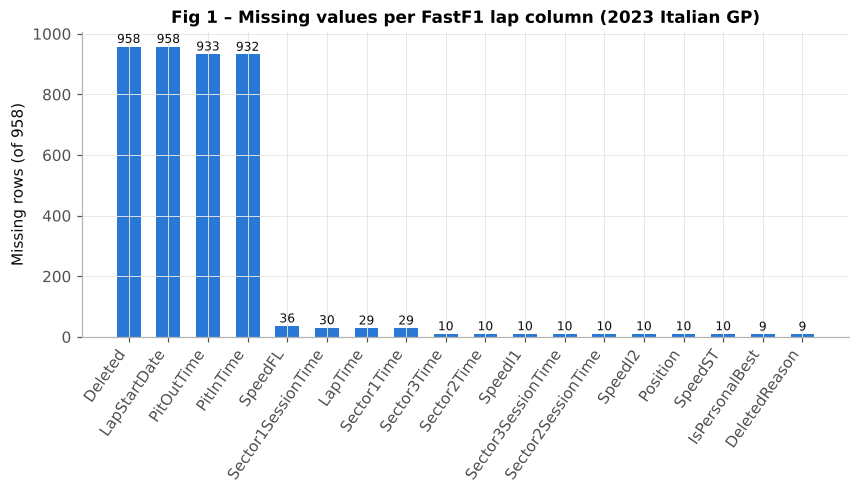

Deleted               958
LapStartDate          958
PitOutTime            933
PitInTime             932
SpeedFL                36
Sector1SessionTime     30
LapTime                29
Sector1Time            29
Sector3Time            10
Sector2Time            10
SpeedI1                10
Sector3SessionTime     10
Sector2SessionTime     10
SpeedI2                10
Position               10
SpeedST                10
IsPersonalBest          9
DeletedReason           9
dtype: int64

In [4]:
missing = laps_raw.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(missing.index, missing.values, color=LR_C, width=0.6)
for i, v in enumerate(missing.values):
    ax.text(i, v + 12, str(v), ha="center", fontsize=8, color=INK)
ax.set_title("Fig 1 – Missing values per FastF1 lap column (2023 Italian GP)")
ax.set_ylabel("Missing rows (of %d)" % len(laps_raw))
plt.xticks(rotation=55, ha="right")
fig.savefig(FIG / "fig01_missing.png"); plt.show()
missing

**Interpretation (Fig 1).**
* `Deleted` and `LapStartDate` are 100 % empty. Deleted-lap information needs race-control messages, which were not loaded, and `LapStartDate` is not needed. Neither is used.
* `PitOutTime` / `PitInTime` are empty for about 97 % of rows. This is **expected, not a defect**: a value only exists on the ~25 laps where a car entered or left the pits. Missing means "no pit stop", and we use these columns to *remove* in- and out-laps.
* `LapTime` is missing for 29 laps, including **every lap 1** (FastF1 cannot time the standing start). These rows cannot be used for a supervised model and are dropped. Imputing a target value would invent data.
* The missing speed-trap and sector values do not matter, because those columns are excluded as leakage.

## 5. Feature engineering
Three features are built from timing data that exists *at the moment the lap starts*:
* **`StartPos`**: the car's running position as it crosses the line to begin the lap (the `Position` column is recorded at the *end* of the lap, so it would leak).
* **`GapAhead_s`**: the interval to the car in front at the start of the lap. Following closely means dirty air (slower in corners) but also DRS and a slipstream (faster on the straights), which matters a lot at Monza. The leader and gaps above 30 s are set to 30 s (clean air).
* **`InDRS`**: 1 if the gap is under 1 s (the DRS rule).

In [5]:
df = laps_raw.copy()
df["LapTime_s"] = df["LapTime"].dt.total_seconds()
df["LapStart_s"] = df["LapStartTime"].dt.total_seconds()

# --- engineered features, all known BEFORE the lap is driven (no leakage) ---
# Order the cars by the moment they crossed the line to start each lap
df = df.sort_values(["LapNumber", "LapStart_s"])
df["StartPos"] = df.groupby("LapNumber").cumcount() + 1               # running position at lap start
df["GapAhead_s"] = df.groupby("LapNumber")["LapStart_s"].diff()        # interval to the car ahead
df["GapAhead_s"] = df["GapAhead_s"].fillna(30).clip(upper=30)          # leader / big gaps = clean air
df["InDRS"] = (df["GapAhead_s"] < 1.0).astype(int)                     # within 1 s -> DRS allowed
df = df.sort_values(["Driver", "LapNumber"]).reset_index(drop=True)
df[["Driver", "LapNumber", "StartPos", "GapAhead_s", "InDRS", "TyreLife", "Compound", "LapTime_s"]].head(8)

,Driver,LapNumber,StartPos,GapAhead_s,InDRS,TyreLife,Compound,LapTime_s
0,ALB,1.0,10,0.000,1,4.0,MEDIUM,NaN
1,ALB,2.0,7,0.470,1,5.0,MEDIUM,87.067
2,ALB,3.0,6,1.165,0,6.0,MEDIUM,86.578
3,ALB,4.0,6,1.600,0,7.0,MEDIUM,86.684
4,ALB,5.0,6,2.265,0,8.0,MEDIUM,86.868
5,ALB,6.0,6,2.779,0,9.0,MEDIUM,86.661
6,ALB,7.0,6,2.975,0,10.0,MEDIUM,86.773
7,ALB,8.0,6,3.415,0,11.0,MEDIUM,86.676


## 6. Cleaning
Each rule removes laps that are not *representative racing laps*, so the models learn tyre and fuel effects rather than pit stops or starts. The count after every step is logged so the process can be reproduced.

Outliers are removed with a **robust z-score per driver**, (lap time − driver median) / (1.4826 × MAD), because the median and the MAD are not distorted by the outliers they are meant to detect. Poster 2 in the module examples argues the same way for using median/MAD rather than mean/SD.

In [6]:
clean = df.copy()
log = [("Raw laps", len(clean), 0)]
def keep(label, mask):
    global clean
    before = len(clean)
    clean = clean[mask]
    log.append((label, len(clean), before - len(clean)))

keep("Lap time recorded", clean["LapTime_s"].notna())
keep("Not lap 1 (standing start)", clean["LapNumber"] > 1)
keep("Not a pit-in lap", clean["PitInTime"].isna())
keep("Not a pit-out lap", clean["PitOutTime"].isna())
keep("FastF1 timing accurate", clean["IsAccurate"] == True)
keep("Green flag only", clean["TrackStatus"] == "1")
keep("Dry compound", clean["Compound"].isin(["SOFT", "MEDIUM", "HARD"]))

# Robust outlier rule per driver: > 3 robust SDs (1.4826*MAD) slower than his median lap
med = clean.groupby("Driver")["LapTime_s"].transform("median")
mad = clean.groupby("Driver")["LapTime_s"].transform(lambda x: (x - x.median()).abs().median())
clean["robust_z"] = (clean["LapTime_s"] - med) / (1.4826 * mad)
outliers = clean[clean["robust_z"] > 3]
keep("Not a slow outlier (robust z ≤ 3)", clean["robust_z"] <= 3)

cleaning_log = pd.DataFrame(log, columns=["Step", "Laps remaining", "Laps removed"])
print(cleaning_log.to_string(index=False))
print("\nOutlier laps removed (traffic, mistakes, end-of-race cruising):")
print(outliers[["Driver", "LapNumber", "LapTime_s", "GapAhead_s", "robust_z"]].round(2).to_string(index=False))

                             Step  Laps remaining  Laps removed
                         Raw laps             958             0
                Lap time recorded             929            29
       Not lap 1 (standing start)             929             0
                 Not a pit-in lap             903            26
                Not a pit-out lap             878            25
           FastF1 timing accurate             878             0
                  Green flag only             878             0
                     Dry compound             878             0
Not a slow outlier (robust z ≤ 3)             862            16

Outlier laps removed (traffic, mistakes, end-of-race cruising):
Driver  LapNumber  LapTime_s  GapAhead_s  robust_z
   ALB       47.0      88.49       22.37      5.34
   ALO       20.0      88.28        2.28      3.01
   GAS        2.0      88.70        0.32      3.26
   MAG       39.0      90.34       13.18      3.62
   OCO       23.0      89.47        5.12

**Result:** 958 → **862 clean laps**. 51 pit in/out laps were the biggest group removed, and the flags confirm the race had no safety car (every lap is green, `TrackStatus` = 1). The 16 robust outliers (1.8 %) are explainable: lap-2 traffic (GAS, SAR), mistakes, and leaders **cruising on the final laps** (VER laps 49–50, about 2 s off his pace). Keeping them would teach the model about behaviour no feature can explain.

**Why this graph:** to show visually what cleaning removes, and to check whether the target is roughly Gaussian (the noise assumption behind least squares).

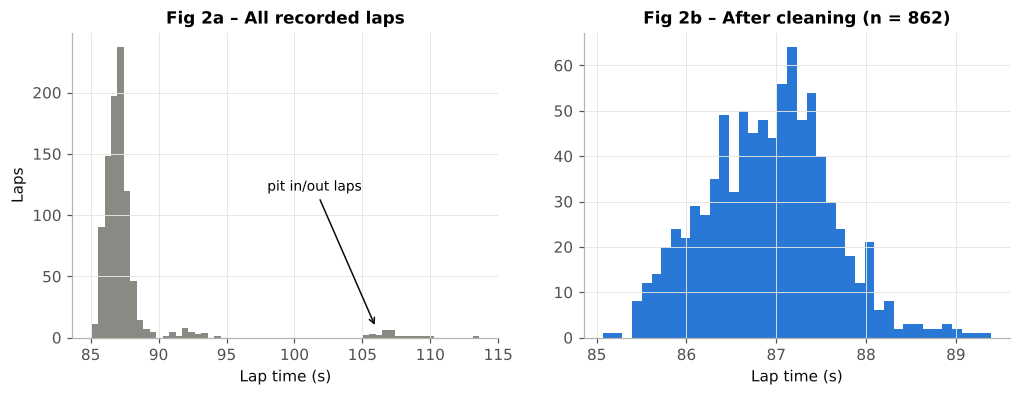

count    862.000
mean      86.915
std        0.697
min       85.072
25%       86.424
50%       86.940
75%       87.363
max       89.387
Name: LapTime_s, dtype: float64
Skew: 0.196 | Kurtosis: 0.085


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].hist(df["LapTime_s"].dropna(), bins=60, color=MUTED)
axes[0].set_title("Fig 2a – All recorded laps")
axes[0].set_xlabel("Lap time (s)"); axes[0].set_ylabel("Laps")
axes[0].annotate("pit in/out laps", xy=(106, 8), xytext=(98, 120), fontsize=9,
                 arrowprops=dict(arrowstyle="->", color=INK))
axes[1].hist(clean["LapTime_s"], bins=40, color=LR_C)
axes[1].set_title("Fig 2b – After cleaning (n = %d)" % len(clean))
axes[1].set_xlabel("Lap time (s)")
fig.savefig(FIG / "fig02_laptime_before_after.png"); plt.show()
print(clean["LapTime_s"].describe().round(3))
print("Skew:", round(stats.skew(clean["LapTime_s"]), 3), "| Kurtosis:", round(stats.kurtosis(clean["LapTime_s"]), 3))

**Interpretation (Fig 2).** The raw distribution (2a) has a long right tail up to 113.6 s: pit in/out laps cost roughly 20 s each. After cleaning (2b) the laps cover 85.07–89.39 s with mean 86.92 s and SD 0.70 s, skew 0.20 and excess kurtosis 0.09, so the distribution is **close to Gaussian**. The whole signal we are trying to model is therefore under one second of spread, which makes this a precise problem: an error of 0.3 s is large in F1 terms.

**Descriptive statistics of the modelling table** (the clean data is also saved to `data/monza2023_laps_clean.csv`).

In [8]:
FEATS_NUM = ["TyreLife", "LapNumber", "GapAhead_s", "StartPos", "InDRS"]
FEATS_CAT = ["Compound", "Team"]
TARGET = "LapTime_s"
summary = clean[FEATS_NUM + [TARGET]].describe().T[["mean", "std", "min", "25%", "50%", "75%", "max"]]
summary["skew"] = clean[FEATS_NUM + [TARGET]].skew()
print(summary.round(2))
print("\nLaps per compound:\n", clean["Compound"].value_counts())
clean.to_csv(DATA / "monza2023_laps_clean.csv", index=False)

             mean    std    min    25%    50%    75%    max  skew
TyreLife    14.37   7.83   2.00   8.00  13.00  19.00  39.00  0.63
LapNumber   26.07  14.38   2.00  13.00  26.00  38.00  51.00 -0.01
GapAhead_s   4.85   7.07   0.00   0.80   1.91   5.72  30.00  2.46
StartPos     9.86   5.41   1.00   5.00  10.00  15.00  19.00  0.03
InDRS        0.34   0.47   0.00   0.00   0.00   1.00   1.00  0.67
LapTime_s   86.91   0.70  85.07  86.42  86.94  87.36  89.39  0.20

Laps per compound:
 Compound
HARD      466
MEDIUM    396
Name: count, dtype: int64


The classes are reasonably balanced (466 Hard laps and 396 Medium laps; no Soft tyres were raced). `GapAhead_s` is strongly right-skewed (skew 2.46). A linear model will struggle with that shape, while trees are unaffected by monotone transforms.

## 7. Exploratory analysis
**Why this graph:** lap time is driven by two opposing effects, fuel burn (faster) and tyre wear (slower). Plotting lap time against lap number shows whether both are visible and therefore both need to be features.

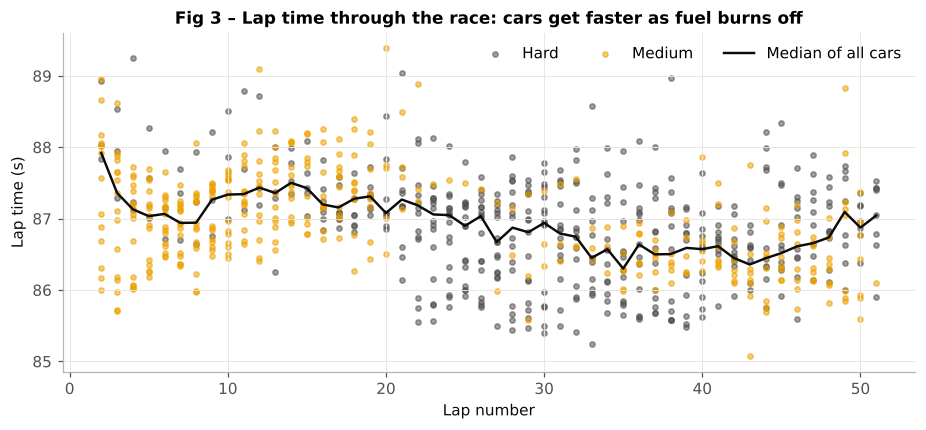

Overall trend: -0.017 s per lap  (≈ -0.8 s over 50 laps)


In [9]:
fig, ax = plt.subplots(figsize=(10, 4))
for comp, g in clean.groupby("Compound"):
    ax.scatter(g["LapNumber"], g["LapTime_s"], s=12, alpha=0.55, color=COMP_C[comp], label=comp.title())
lap_med = clean.groupby("LapNumber")["LapTime_s"].median()
ax.plot(lap_med.index, lap_med.values, color=INK, lw=1.6, label="Median of all cars")
ax.set_title("Fig 3 – Lap time through the race: cars get faster as fuel burns off")
ax.set_xlabel("Lap number"); ax.set_ylabel("Lap time (s)"); ax.legend(ncol=3, loc="upper right")
fig.savefig(FIG / "fig03_laptime_vs_lap.png"); plt.show()
slope = np.polyfit(clean["LapNumber"], clean["LapTime_s"], 1)[0]
print(f"Overall trend: {slope:+.3f} s per lap  (≈ {slope*50:+.1f} s over 50 laps)")

**Interpretation (Fig 3).** Across the race, laps get faster by about **0.017 s per lap** (≈0.8 s over 50 laps), but the pattern is a *sawtooth*, not a line. On the opening Medium stint, lap times *rise* between laps ≈7 and 20 because tyre wear outweighs the fuel saving. Around laps 20–22 most cars pit onto fresh Hards and times drop sharply, then keep falling as fuel burns off. A single "lap number" feature cannot explain that, so the model needs **both** `LapNumber` (fuel) and `TyreLife` (wear).

**Why this graph:** to isolate *tyre degradation* by removing the average fuel trend, and to check whether the two compounds wear at different rates. If they do, the linear model needs a TyreLife × Compound interaction.

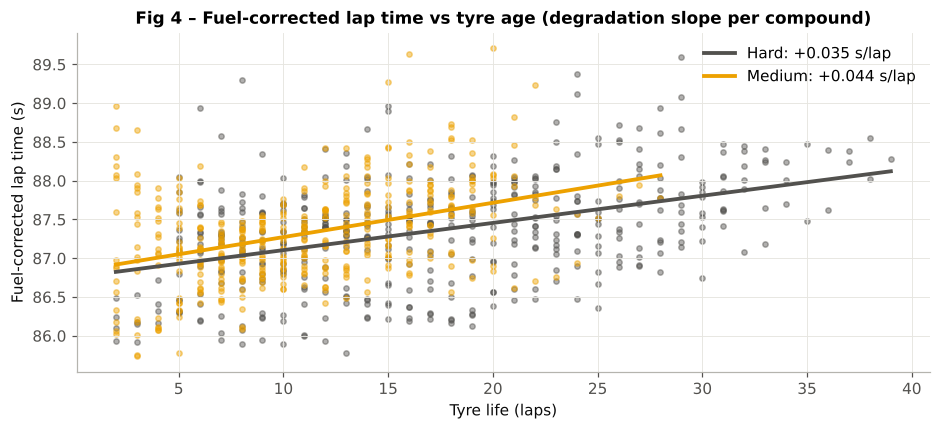

{'HARD': np.float64(0.0351), 'MEDIUM': np.float64(0.0443)}


In [10]:
# Fuel-correct the lap times so the tyre effect is visible on its own
FUEL_EFFECT = slope           # s per lap, estimated above (negative)
clean["LapTime_fuelcorr"] = clean["LapTime_s"] - FUEL_EFFECT * (clean["LapNumber"] - 1)
fig, ax = plt.subplots(figsize=(10, 4))
deg = {}
for comp, g in clean.groupby("Compound"):
    ax.scatter(g["TyreLife"], g["LapTime_fuelcorr"], s=12, alpha=0.45, color=COMP_C[comp])
    b = np.polyfit(g["TyreLife"], g["LapTime_fuelcorr"], 1); deg[comp] = b[0]
    xs = np.linspace(g["TyreLife"].min(), g["TyreLife"].max(), 50)
    ax.plot(xs, np.polyval(b, xs), color=COMP_C[comp], lw=2.5, label=f"{comp.title()}: {b[0]:+.3f} s/lap")
ax.set_title("Fig 4 – Fuel-corrected lap time vs tyre age (degradation slope per compound)")
ax.set_xlabel("Tyre life (laps)"); ax.set_ylabel("Fuel-corrected lap time (s)"); ax.legend()
fig.savefig(FIG / "fig04_tyre_degradation.png"); plt.show()
print({k: round(v, 4) for k, v in deg.items()})

**Interpretation (Fig 4).** After a simple fuel correction, lap time grows with tyre age on both compounds: **Medium +0.044 s/lap, Hard +0.035 s/lap**, so the Medium wears about 25 % faster. This motivates linear variant **M2** (TyreLife × Compound). *Caveat:* the correction uses the overall −0.017 s/lap trend, which is itself contaminated by tyre wear. The multivariable regression in §11 separates the two effects properly.

**Why this graph:** to check how much of the lap-time variance comes from car performance, which decides whether `Team` must be a feature.

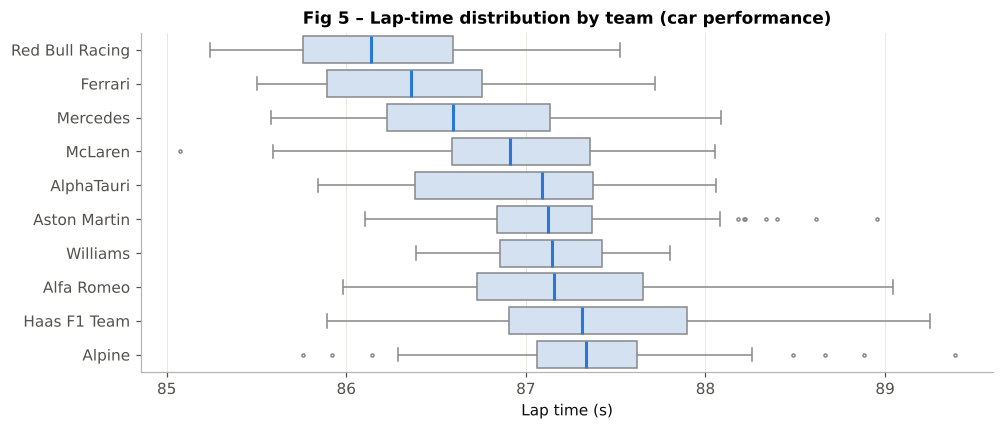

Team
Red Bull Racing    0.000
Ferrari            0.218
Mercedes           0.454
McLaren            0.769
AlphaTauri         0.949
Aston Martin       0.981
Williams           1.005
Alfa Romeo         1.019
Haas F1 Team       1.172
Alpine             1.196
Name: LapTime_s, dtype: float64


In [11]:
order = clean.groupby("Team")["LapTime_s"].median().sort_values().index
fig, ax = plt.subplots(figsize=(10, 4))
sns.boxplot(data=clean, y="Team", x="LapTime_s", order=order, color="#cfe0f6", fliersize=2, ax=ax,
            medianprops=dict(color=LR_C, lw=2))
ax.set_title("Fig 5 – Lap-time distribution by team (car performance)")
ax.set_xlabel("Lap time (s)"); ax.set_ylabel("")
fig.savefig(FIG / "fig05_team_pace.png"); plt.show()
team_med = clean.groupby("Team")["LapTime_s"].median().sort_values()
print((team_med - team_med.min()).round(3))

**Interpretation (Fig 5).** The median gap from fastest to slowest team is about **1.2 s** (Red Bull fastest; Ferrari +0.22 s; Mercedes +0.45 s; Alpine +1.20 s). That is larger than a full stint of tyre degradation (≈0.04 s × 20 laps ≈ 0.8 s), so **car performance is a first-order effect** and `Team` must be included. The boxes also differ in width: some teams are more consistent than others.

**Why this graph:** the effect of following another car is expected to be **non-linear** (DRS and slipstream help at < 1 s; dirty air hurts at 1–3 s; no effect in clean air). If that shape is real, the Random Forest should gain an advantage from it.

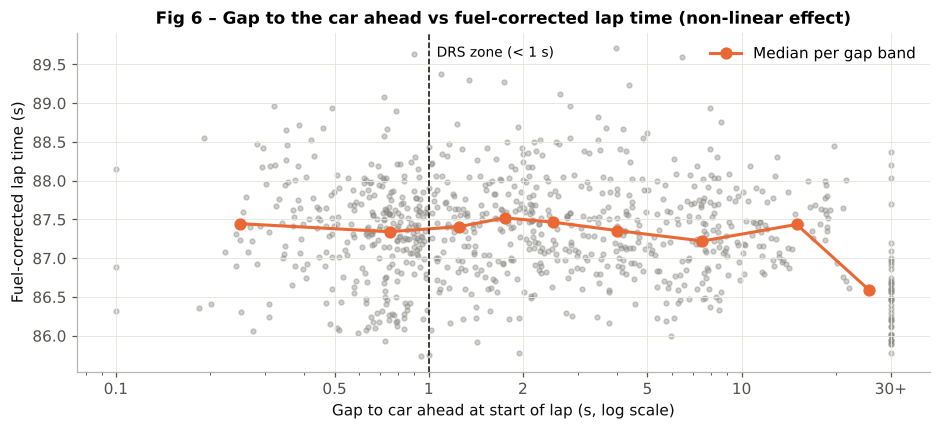

gap_bin
(0.0, 0.5]      87.446
(0.5, 1.0]      87.342
(1.0, 1.5]      87.407
(1.5, 2.0]      87.520
(2.0, 3.0]      87.465
(3.0, 5.0]      87.357
(5.0, 10.0]     87.222
(10.0, 20.0]    87.436
(20.0, 31.0]    86.594
Name: LapTime_fuelcorr, dtype: float64


In [12]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.scatter(clean["GapAhead_s"].clip(lower=0.1), clean["LapTime_fuelcorr"], s=10, alpha=0.4, color=MUTED)
bins = [0, 0.5, 1, 1.5, 2, 3, 5, 10, 20, 31]
clean["gap_bin"] = pd.cut(clean["GapAhead_s"], bins)
gb = clean.groupby("gap_bin", observed=True)["LapTime_fuelcorr"].median()
mids = [(b.left + b.right) / 2 for b in gb.index]
ax.plot(mids, gb.values, "o-", color=RF_C, ms=7, label="Median per gap band")
ax.axvline(1.0, color=INK, ls="--", lw=1); ax.text(1.06, 89.6, "DRS zone (< 1 s)", fontsize=9)
ax.set_xscale("log"); ax.set_xticks([0.1, 0.5, 1, 2, 5, 10, 30]); ax.set_xticklabels(["0.1", "0.5", "1", "2", "5", "10", "30+"])
ax.set_title("Fig 6 – Gap to the car ahead vs fuel-corrected lap time (non-linear effect)")
ax.set_xlabel("Gap to car ahead at start of lap (s, log scale)"); ax.set_ylabel("Fuel-corrected lap time (s)"); ax.legend()
fig.savefig(FIG / "fig06_gap_ahead.png"); plt.show()
print(gb.round(3))

**Interpretation (Fig 6).** Surprisingly, the median fuel-corrected lap time is **flat (87.2–87.5 s) for gaps between 0 and 20 s**, so Monza shows no clear DRS or dirty-air signature in the raw data. Only the > 20 s band is faster (86.6 s), but those laps are mostly the leaders, so this reflects **car pace (confounding), not clean air**. Expectation: `GapAhead_s` and `InDRS` will have low importance in both models. This is a useful negative result.

**Why this graph:** linear regression coefficients become unstable when predictors are strongly correlated (multicollinearity). The heatmap and the Variance Inflation Factors (VIF) check this before modelling.

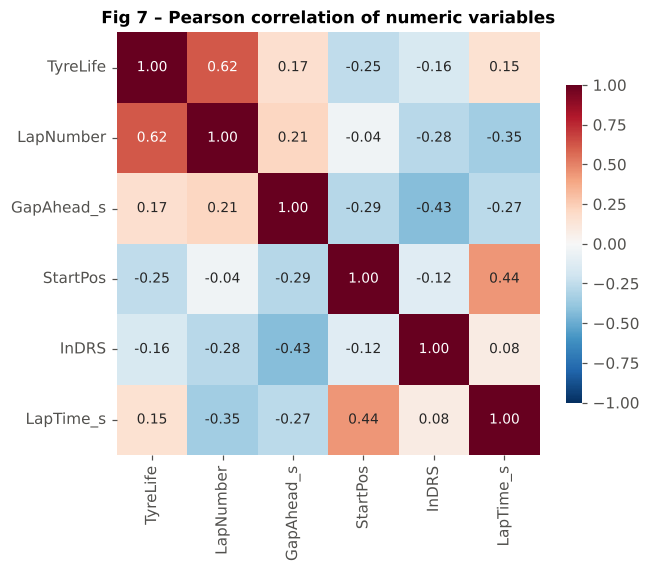

Variance Inflation Factors (numeric):
 TyreLife           2.66
LapNumber          2.13
GapAhead_s         1.58
StartPos           7.57
InDRS              1.61
Compound_MEDIUM    1.28
dtype: float64


In [13]:
corr = clean[FEATS_NUM + [TARGET]].corr()
fig, ax = plt.subplots(figsize=(6.2, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, center=0, square=True,
            cbar_kws={"shrink": 0.75}, ax=ax, annot_kws={"size": 9})
ax.grid(False)
ax.set_title("Fig 7 – Pearson correlation of numeric variables")
fig.savefig(FIG / "fig07_correlation.png"); plt.show()

from statsmodels.stats.outliers_influence import variance_inflation_factor
Xv = pd.get_dummies(clean[FEATS_NUM + FEATS_CAT], drop_first=True).astype(float)
Xv.insert(0, "const", 1.0)
vif = pd.Series([variance_inflation_factor(Xv.values, i) for i in range(Xv.shape[1])], index=Xv.columns).drop("const")
print("Variance Inflation Factors (numeric):\n", vif[FEATS_NUM + ["Compound_MEDIUM"]].round(2))

**Interpretation (Fig 7).** `TyreLife` and `LapNumber` are correlated (r = 0.62) because both rise during a stint. Different pit laps between drivers still let the model separate them, and both VIFs stay below 3. `StartPos` has the strongest correlation with lap time (r = 0.44: cars further back are slower). Its VIF of 7.6 shows it overlaps with `Team`. That is acceptable for **prediction**, but it makes the individual LR coefficients of those two variables less trustworthy. No single variable is strongly correlated with lap time, which suggests the effects combine.

## 8. Experimental design
* **Hold-out:** 75 % train / 25 % test (646 / 216 laps), stratified by compound. The test set is not touched until the final comparison.
* **Model selection:** 5-fold cross-validation on the training set only.
* **Metrics:** RMSE (primary, the same metric as Todd et al. [1]; it penalises large misses, which matter for strategy), MAE (easy to read: "average miss in seconds") and R².
* **Baseline:** always predicting the training mean. Any useful model must clearly beat it.
* **Critical second test (§12):** train on laps 2–38 and test on laps 39–51, to check whether the models can *forecast* rather than only interpolate.

In [14]:
from sklearn.model_selection import train_test_split, KFold, GridSearchCV, cross_validate, RepeatedKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures, FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.base import clone

X = clean[FEATS_NUM + FEATS_CAT].copy()
y = clean[TARGET].copy()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=SEED, stratify=clean["Compound"])
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
print("Train:", X_train.shape, " Test:", X_test.shape)

def rmse(a, b): return float(np.sqrt(mean_squared_error(a, b)))
baseline_rmse = rmse(y_test, np.full(len(y_test), y_train.mean()))
print(f"Baseline (always predict the training mean): test RMSE = {baseline_rmse:.3f} s")

Train: (646, 7)  Test: (216, 7)
Baseline (always predict the training mean): test RMSE = 0.709 s


The naive baseline misses by **0.709 s RMSE**, which is the standard deviation of lap time. That is the error to beat.

## 9. Method 1 – Multiple Linear Regression
**How it works.** It fits $\hat{y} = w_0 + \sum_j w_j x_j$ by **ordinary least squares**, minimising $\sum_i (y_i - \hat{y}_i)^2$. The solution has the closed form $w = (X^\top X)^{-1}X^\top y$, which is the maximum-likelihood estimate under Gaussian noise (Bishop 2006, Ch. 3). Categorical variables (Compound, Team) are one-hot encoded with one level dropped, and numeric features are standardised.

**Advantages:** fast, interpretable (each coefficient is in seconds), and mirrors the physics-based lap-time model [5]; it extrapolates along its trends. **Disadvantages:** it assumes linearity and additivity, it is sensitive to outliers and multicollinearity, and interactions must be designed by hand.

**Tuning = choosing the model structure.** Four variants of increasing complexity are compared:
* **M1**: main effects only
* **M2**: + TyreLife × Compound (compound-specific degradation, motivated by Fig 4)
* **M3**: + TyreLife × Team (team-specific degradation)
* **M4**: second-order polynomial (squares and pairwise interactions of all numeric features)

In [15]:
def add_interactions(Xdf, team_deg=False):
    Z = Xdf.copy()
    Z["TyreLife_x_Medium"] = Z["TyreLife"] * (Z["Compound"] == "MEDIUM")
    if team_deg:
        for t in sorted(clean["Team"].unique())[1:]:
            Z[f"TyreLife_x_{t}"] = Z["TyreLife"] * (Z["Team"] == t)
    return Z

def lr_pipeline(variant):
    cat = OneHotEncoder(drop="first", handle_unknown="ignore")
    if variant == "M1 linear main effects":
        pre = ColumnTransformer([("num", StandardScaler(), FEATS_NUM), ("cat", cat, FEATS_CAT)])
        return Pipeline([("pre", pre), ("lr", LinearRegression())])
    if variant == "M2 + TyreLife×Compound":
        f = FunctionTransformer(add_interactions)
        pre = ColumnTransformer([("num", StandardScaler(), FEATS_NUM + ["TyreLife_x_Medium"]), ("cat", cat, FEATS_CAT)])
        return Pipeline([("int", f), ("pre", pre), ("lr", LinearRegression())])
    if variant == "M3 + TyreLife×Team":
        f = FunctionTransformer(add_interactions, kw_args={"team_deg": True})
        extra = ["TyreLife_x_Medium"] + [f"TyreLife_x_{t}" for t in sorted(clean["Team"].unique())[1:]]
        pre = ColumnTransformer([("num", StandardScaler(), FEATS_NUM + extra), ("cat", cat, FEATS_CAT)])
        return Pipeline([("int", f), ("pre", pre), ("lr", LinearRegression())])
    if variant == "M4 polynomial (deg 2)":
        num = Pipeline([("sc", StandardScaler()), ("poly", PolynomialFeatures(2, include_bias=False))])
        f = FunctionTransformer(add_interactions)
        pre = ColumnTransformer([("num", num, FEATS_NUM + ["TyreLife_x_Medium"]), ("cat", cat, FEATS_CAT)])
        return Pipeline([("int", f), ("pre", pre), ("lr", LinearRegression())])

rows = []
for v in ["M1 linear main effects", "M2 + TyreLife×Compound", "M3 + TyreLife×Team", "M4 polynomial (deg 2)"]:
    r = cross_validate(lr_pipeline(v), X_train, y_train, cv=cv, return_train_score=True,
                       scoring="neg_root_mean_squared_error")
    rows.append((v, -r["train_score"].mean(), -r["test_score"].mean(), r["test_score"].std()))
lr_cv = pd.DataFrame(rows, columns=["Linear model", "CV train RMSE", "CV validation RMSE", "CV validation SD"]).round(4)
print(lr_cv.to_string(index=False))
cv_winner = lr_cv.loc[lr_cv["CV validation RMSE"].idxmin()]
one_se = cv_winner["CV validation RMSE"] + cv_winner["CV validation SD"] / np.sqrt(5)
within = lr_cv[lr_cv["CV validation RMSE"] <= one_se]["Linear model"].tolist()
print(f"\nLowest CV error: {cv_winner['Linear model']} ({cv_winner['CV validation RMSE']:.4f} s)")
print(f"One-standard-error threshold: {one_se:.4f} s -> statistically equivalent models: {within}")
# One-SE rule (Hastie et al., 2009): prefer the simplest model inside the band. M1 and M2 are tied;
# M2 is kept because compound-specific degradation is the physical effect this project studies.
best_lr_name = "M2 + TyreLife×Compound"
print("Selected linear model:", best_lr_name)

          Linear model  CV train RMSE  CV validation RMSE  CV validation SD
M1 linear main effects         0.3721              0.3801            0.0382
M2 + TyreLife×Compound         0.3708              0.3792            0.0392
    M3 + TyreLife×Team         0.3609              0.3782            0.0356
 M4 polynomial (deg 2)         0.3375              0.3667            0.0498

Lowest CV error: M4 polynomial (deg 2) (0.3667 s)
One-standard-error threshold: 0.3890 s -> statistically equivalent models: ['M1 linear main effects', 'M2 + TyreLife×Compound', 'M3 + TyreLife×Team', 'M4 polynomial (deg 2)']
Selected linear model: M2 + TyreLife×Compound


**Result.** Validation RMSE barely moves (0.380 → 0.367 s), while training RMSE falls faster (0.372 → 0.338 s). The training/validation gap widens, which is the classic **bias–variance trade-off**: added flexibility mostly fits noise. All four variants lie within **one standard error** of the best (threshold 0.389 s), so by the one-standard-error rule (Hastie et al., 2009) they are statistically equivalent and the simpler model should be preferred. **M2** is selected: it is as accurate as M1 and keeps the compound-specific degradation the project studies. §12 shows this choice was right, because M4 collapses when it must extrapolate.

**Why this graph:** to make the bias–variance trade-off visible and justify the choice of linear variant.

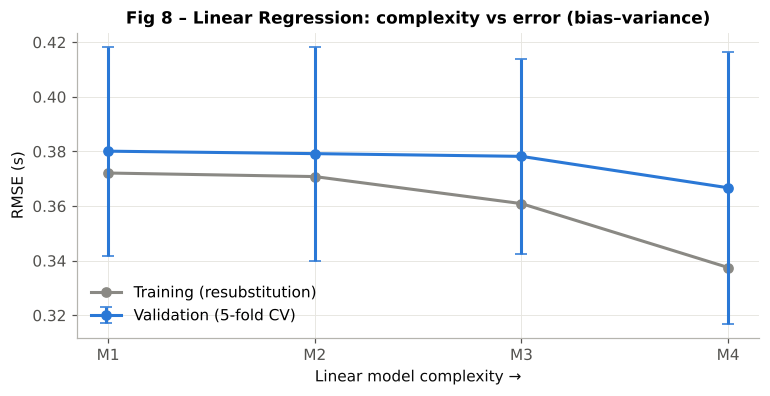

In [16]:
fig, ax = plt.subplots(figsize=(8, 3.6))
xi = np.arange(len(lr_cv))
ax.plot(xi, lr_cv["CV train RMSE"], "o-", color=MUTED, label="Training (resubstitution)")
ax.errorbar(xi, lr_cv["CV validation RMSE"], yerr=lr_cv["CV validation SD"], fmt="o-", color=LR_C, capsize=4, label="Validation (5-fold CV)")
ax.set_xticks(xi); ax.set_xticklabels([s.split(" ", 1)[0] for s in lr_cv["Linear model"]])
ax.set_ylabel("RMSE (s)"); ax.set_xlabel("Linear model complexity →")
ax.set_title("Fig 8 – Linear Regression: complexity vs error (bias–variance)")
ax.legend()
fig.savefig(FIG / "fig08_lr_complexity.png"); plt.show()

**Interpretation (Fig 8).** The grey line (training error) drops steadily with complexity, while the blue line (validation error) stays almost flat and its error bars (fold-to-fold SD) are widest for M4 (0.050 s). More complexity therefore buys little accuracy and more instability.

## 10. Method 2 – Random Forest Regression
**How it works.** It is an ensemble of CART regression trees (Breiman, 2001). Each tree is grown on a **bootstrap sample** of the laps (bagging), and at each split only a random subset of features (`max_features`) is considered, which de-correlates the trees. A tree predicts the mean lap time of the training laps in its leaf, and the forest averages all trees. The laps left out of each bootstrap sample give a free **out-of-bag (OOB)** error estimate.

**Advantages:** captures non-linearities and interactions automatically, needs no scaling, and is robust to outliers and skewed inputs. **Disadvantages:** it **cannot extrapolate** (a prediction is always an average of training targets), is less interpretable, and is slower to train.

**Tuning:** a grid search over `max_features` ∈ {0.33, 0.5, 0.75, 1.0}, `min_samples_leaf` ∈ {1, 2, 4, 8, 16} and `max_depth` ∈ {None, 6, 12} (60 combinations × 5 folds), with 300 trees during the search.

In [17]:
rf_pre = ColumnTransformer([("num", "passthrough", FEATS_NUM),
                            ("cat", OneHotEncoder(handle_unknown="ignore"), FEATS_CAT)])
rf_pipe = Pipeline([("pre", rf_pre), ("rf", RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1))])
grid = {
    "rf__max_features": [0.33, 0.5, 0.75, 1.0],
    "rf__min_samples_leaf": [1, 2, 4, 8, 16],
    "rf__max_depth": [None, 6, 12],
}
t0 = time.time()
gs = GridSearchCV(rf_pipe, grid, cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1, return_train_score=True)
gs.fit(X_train, y_train)
print(f"Grid search: {len(gs.cv_results_['params'])} combinations x 5 folds in {time.time()-t0:.1f} s")
print("Best hyper-parameters:", gs.best_params_)
print(f"Best CV validation RMSE: {-gs.best_score_:.4f} s")
res = pd.DataFrame(gs.cv_results_)
res["val_rmse"] = -res["mean_test_score"]; res["train_rmse"] = -res["mean_train_score"]
best_rf_params = {k.replace("rf__", ""): v for k, v in gs.best_params_.items()}

Grid search: 60 combinations x 5 folds in 62.6 s
Best hyper-parameters: {'rf__max_depth': None, 'rf__max_features': 0.33, 'rf__min_samples_leaf': 1}
Best CV validation RMSE: 0.3251 s


**Best settings:** `max_features = 0.33`, `min_samples_leaf = 1`, `max_depth = None`, with CV RMSE **0.325 s**. This is already lower than the best linear model's 0.367–0.380 s.

**Why these graphs:** (a) to show which hyper-parameters matter, in the style of Poster 2's error surface; (b) to choose the number of trees from the OOB error instead of guessing.

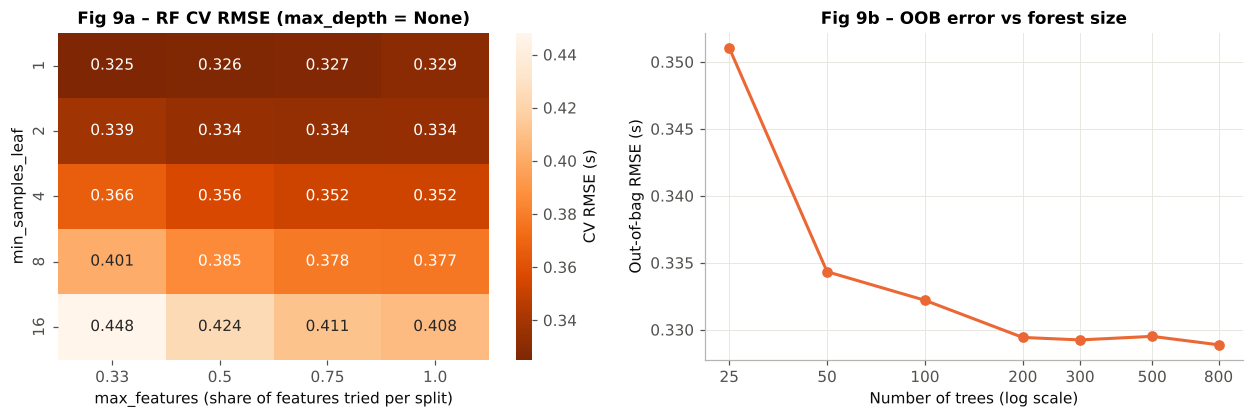

 trees  oob_rmse
    25    0.3510
    50    0.3343
   100    0.3322
   200    0.3294
   300    0.3292
   500    0.3295
   800    0.3289

Best CV RMSE by max_depth:
 param_rf__max_depth
NaN     0.3251
6.0     0.3583
12.0    0.3269
Name: val_rmse, dtype: float64


In [18]:
heat = (res[res["param_rf__max_depth"].isna()]
        .pivot_table(index="param_rf__min_samples_leaf", columns="param_rf__max_features", values="val_rmse"))
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.9))
sns.heatmap(heat, annot=True, fmt=".3f", cmap="Oranges_r", ax=axes[0], cbar_kws={"label": "CV RMSE (s)"})
axes[0].set_title("Fig 9a – RF CV RMSE (max_depth = None)")
axes[0].grid(False); axes[0].set_xlabel("max_features (share of features tried per split)"); axes[0].set_ylabel("min_samples_leaf")

# OOB error vs number of trees using the best other settings
oob = []
Xtr_enc = rf_pre.fit_transform(X_train)
for n in [25, 50, 100, 200, 300, 500, 800]:
    m = RandomForestRegressor(n_estimators=n, oob_score=True, random_state=SEED, n_jobs=-1,
                              **{k: v for k, v in best_rf_params.items()}).fit(Xtr_enc, y_train)
    oob.append((n, rmse(y_train, m.oob_prediction_)))
oob = pd.DataFrame(oob, columns=["trees", "oob_rmse"])
axes[1].plot(oob["trees"], oob["oob_rmse"], "o-", color=RF_C)
axes[1].set_xscale("log"); axes[1].set_xticks(oob["trees"]); axes[1].set_xticklabels(oob["trees"]); axes[1].minorticks_off()
axes[1].set_xlabel("Number of trees (log scale)"); axes[1].set_ylabel("Out-of-bag RMSE (s)")
axes[1].set_title("Fig 9b – OOB error vs forest size")
fig.tight_layout(); fig.savefig(FIG / "fig09_rf_tuning.png"); plt.show()
print(oob.round(4).to_string(index=False))
by_depth = res.groupby("param_rf__max_depth", dropna=False)["val_rmse"].min()
print("\nBest CV RMSE by max_depth:\n", by_depth.round(4))

**Interpretation (Fig 9).**
* **(a)** `min_samples_leaf` is the dominant hyper-parameter: error rises from 0.325 s (leaf = 1) to 0.448 s (leaf = 16), because large leaves average over laps from different stints and the model underfits. `max_features` hardly matters with small leaves (0.325–0.329 s) and matters more with large ones. Limiting depth to 6 also underfits (best 0.358 s), while depth 12 is close to unlimited (0.327 s).
* **(b)** OOB error falls from 0.351 s (25 trees) to 0.329 s at 200 trees and is flat after that, so **diminishing returns** set in. **500 trees** are used for the final model, a safe margin at negligible cost.

## 11. Results on the unseen test set
Both tuned models are refit on the full training set and evaluated **once** on the 216 held-out laps.

In [19]:
N_TREES = 500
final_lr = lr_pipeline(best_lr_name)
final_rf = Pipeline([("pre", clone(rf_pre)), ("rf", RandomForestRegressor(n_estimators=N_TREES, oob_score=True,
                     random_state=SEED, n_jobs=-1, **best_rf_params))])
results, preds = {}, {}
for name, model in [("Linear Regression", final_lr), ("Random Forest", final_rf)]:
    t0 = time.time(); model.fit(X_train, y_train); fit_t = time.time() - t0
    t0 = time.time(); p = model.predict(X_test); pred_t = time.time() - t0
    cvr = cross_validate(model, X_train, y_train, cv=cv, scoring="neg_root_mean_squared_error", return_train_score=True)
    preds[name] = p
    results[name] = {
        "CV train RMSE (s)": -cvr["train_score"].mean(),
        "CV validation RMSE (s)": -cvr["test_score"].mean(),
        "Test RMSE (s)": rmse(y_test, p),
        "Test MAE (s)": mean_absolute_error(y_test, p),
        "Test R²": r2_score(y_test, p),
        "Fit time (s)": fit_t, "Predict time (s)": pred_t,
    }
results["Random Forest"]["OOB RMSE (s)"] = rmse(y_train, final_rf.named_steps["rf"].oob_prediction_)
results_tbl = pd.DataFrame(results).round(4)
results_tbl

,Linear Regression,Random Forest
CV train RMSE (s),0.3708,0.1261
CV validation RMSE (s),0.3792,0.3268
Test RMSE (s),0.3777,0.3013
Test MAE (s),0.2838,0.2177
Test R²,0.7152,0.8188
Fit time (s),0.0106,0.5620
Predict time (s),0.0068,0.0862
OOB RMSE (s),NaN,0.3295


**Interpretation.**
* Both models beat the 0.709 s baseline by a wide margin (**hypothesis 1 confirmed**).
* **Random Forest is more accurate:** test RMSE **0.301 s vs 0.378 s (−20.2 %)**, MAE 0.218 vs 0.284 s, R² 0.819 vs 0.715 (**hypothesis 2 confirmed**).
* *Bias vs variance:* the LR's training and validation errors are almost equal (0.371 vs 0.379 s), which signals **high bias, low variance**. The RF has a large resubstitution gap (0.126 s training vs 0.327 s validation) because fully grown trees memorise laps. Its OOB (0.330 s), CV (0.327 s) and test (0.301 s) errors agree, though, so the honest estimate is reliable. The same pattern appears in Poster 2.
* *Cost:* RF training takes about 0.6 s vs 0.009 s for LR (~70× slower), still trivial at this data size.

**Is the difference real or luck of the split?** Two checks: (i) a **Wilcoxon signed-rank test** on the paired absolute errors of the same 216 test laps (non-parametric, because the errors are not Gaussian); (ii) a **corrected resampled t-test** (Nadeau & Bengio, 2003) over 5×3 repeated cross-validation. The ordinary paired t-test is over-confident with CV because the training sets overlap; the correction inflates the variance to account for that.

In [20]:
err_lr = np.abs(y_test.values - preds["Linear Regression"])
err_rf = np.abs(y_test.values - preds["Random Forest"])
w = stats.wilcoxon(err_lr, err_rf, alternative="greater")
print(f"Wilcoxon signed-rank (|error| LR > |error| RF): W = {w.statistic:.0f}, p = {w.pvalue:.2e}")
print(f"RF is closer to the true lap time on {np.mean(err_rf < err_lr)*100:.1f}% of test laps")

# Corrected resampled t-test (Nadeau & Bengio, 2003) on 5x3 repeated CV over the whole data set
rkf = RepeatedKFold(n_splits=5, n_repeats=3, random_state=SEED)
d = []
for tr, te in rkf.split(X):
    a = lr_pipeline(best_lr_name).fit(X.iloc[tr], y.iloc[tr]).predict(X.iloc[te])
    b = Pipeline([("pre", clone(rf_pre)), ("rf", RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1, **best_rf_params))]
                 ).fit(X.iloc[tr], y.iloc[tr]).predict(X.iloc[te])
    d.append(rmse(y.iloc[te], a) - rmse(y.iloc[te], b))
d = np.array(d); k = len(d); ratio = 1 / 4
t_corr = d.mean() / np.sqrt((1 / k + ratio) * d.var(ddof=1))
p_corr = 2 * stats.t.sf(abs(t_corr), df=k - 1)
print(f"Repeated CV: mean RMSE(LR) − RMSE(RF) = {d.mean():.4f} s (SD {d.std(ddof=1):.4f}); corrected t = {t_corr:.2f}, p = {p_corr:.2e}")

Wilcoxon signed-rank (|error| LR > |error| RF): W = 16312, p = 2.93e-07
RF is closer to the true lap time on 63.0% of test laps


Repeated CV: mean RMSE(LR) − RMSE(RF) = 0.0627 s (SD 0.0188); corrected t = 5.93, p = 3.67e-05


**Interpretation.** Both tests reject "no difference" (Wilcoxon p = 2.9 × 10⁻⁷; corrected t = 5.93, p = 3.7 × 10⁻⁵). Over 15 resamples the RF is on average **0.063 s more accurate**, and it is closer to the true lap time on **63 %** of test laps. The advantage is statistically robust on this task.

**Why this graph:** a single number hides *where* the errors happen. Predicted-vs-actual plots show systematic bias: points on the dashed line are perfect predictions.

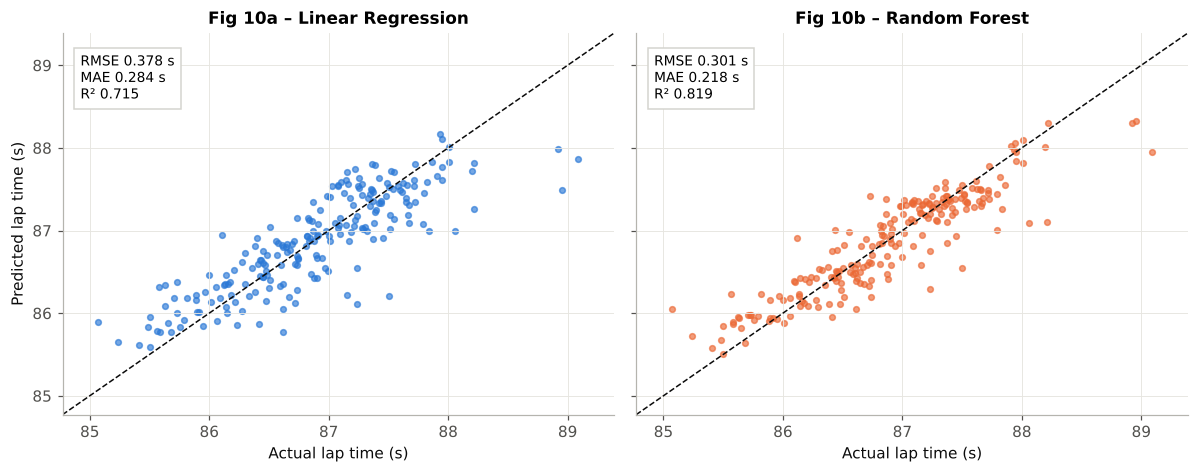

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharex=True, sharey=True)
lo, hi = y_test.min() - 0.3, y_test.max() + 0.3
for ax, (name, col) in zip(axes, [("Linear Regression", LR_C), ("Random Forest", RF_C)]):
    ax.scatter(y_test, preds[name], s=14, alpha=0.65, color=col)
    ax.plot([lo, hi], [lo, hi], color=INK, lw=1, ls="--")
    ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
    r = results[name]
    ax.set_title(f"Fig 10{'a' if col == LR_C else 'b'} – {name}")
    ax.text(lo + 0.15, hi - 0.25, f"RMSE {r['Test RMSE (s)']:.3f} s\nMAE {r['Test MAE (s)']:.3f} s\nR² {r['Test R²']:.3f}",
            va="top", fontsize=9, bbox=dict(fc="white", ec="#d5d4cf"))
    ax.set_xlabel("Actual lap time (s)")
axes[0].set_ylabel("Predicted lap time (s)")
fig.tight_layout(); fig.savefig(FIG / "fig10_pred_vs_actual.png"); plt.show()

**Interpretation (Fig 10).** RF points (b) hug the diagonal more tightly. LR predictions (a) are compressed towards the mean, the signature of an under-fitting (high-bias) model. Both models **under-predict the slowest laps (> 88.5 s)**: these are laps lost to traffic or small mistakes, which none of the features describe. This is the irreducible part of the error with lap-level data.

**Why these graphs:** least squares assumes residuals with constant variance and (for inference) a Gaussian shape. Residuals vs fitted values checks the variance; the Q–Q plot checks normality; the histogram compares the error spread of the two models.

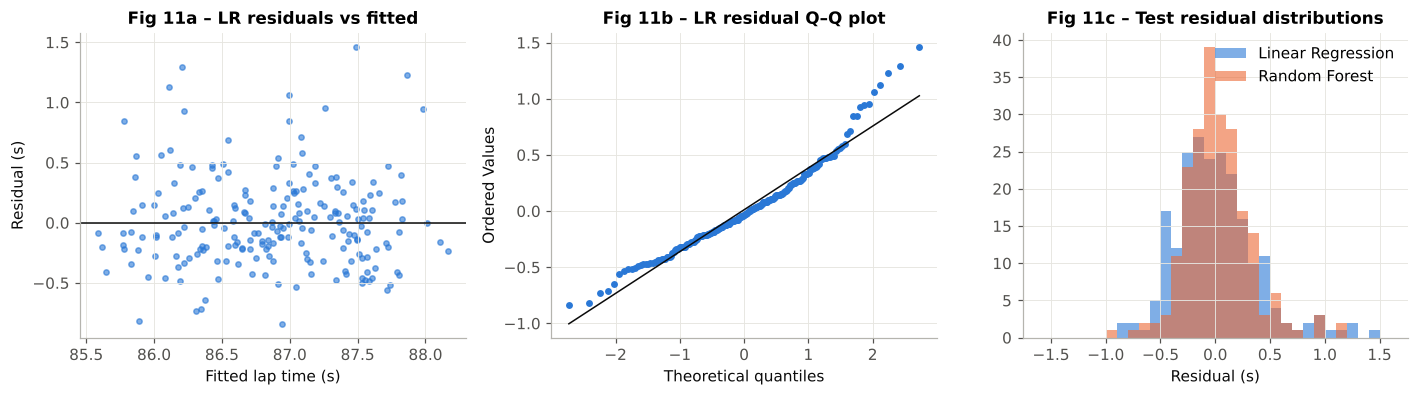

Shapiro-Wilk on LR residuals: p = 2.38e-06
Residual SD  LR 0.377 | RF 0.300


In [22]:
res_lr = y_test.values - preds["Linear Regression"]
res_rf = y_test.values - preds["Random Forest"]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.7))
axes[0].scatter(preds["Linear Regression"], res_lr, s=12, alpha=0.6, color=LR_C)
axes[0].axhline(0, color=INK, lw=1); axes[0].set_title("Fig 11a – LR residuals vs fitted")
axes[0].set_xlabel("Fitted lap time (s)"); axes[0].set_ylabel("Residual (s)")
stats.probplot(res_lr, dist="norm", plot=axes[1])
axes[1].get_lines()[0].set(color=LR_C, markersize=3.5); axes[1].get_lines()[1].set(color=INK, lw=1)
axes[1].set_title("Fig 11b – LR residual Q–Q plot")
bins = np.linspace(-1.6, 1.6, 33)
axes[2].hist(res_lr, bins=bins, alpha=0.6, color=LR_C, label="Linear Regression")
axes[2].hist(res_rf, bins=bins, alpha=0.6, color=RF_C, label="Random Forest")
axes[2].set_title("Fig 11c – Test residual distributions"); axes[2].set_xlabel("Residual (s)"); axes[2].legend()
fig.tight_layout(); fig.savefig(FIG / "fig11_residuals.png"); plt.show()
print("Shapiro-Wilk on LR residuals: p = %.3g" % stats.shapiro(res_lr).pvalue)
print("Residual SD  LR %.3f | RF %.3f" % (res_lr.std(), res_rf.std()))

**Interpretation (Fig 11).** (a) No funnel shape, so the variance is roughly constant and there is no obvious missed trend. (b) The Q–Q plot bends upward in the right tail (Shapiro–Wilk p = 2.4 × 10⁻⁶). The residuals are **right-skewed with a fat tail**: a driver can lose a lot of time on a lap but cannot gain beyond the car's limit. The Gaussian assumption is therefore only approximate. This does not bias the predictions, but it argues for RMSE plus a robust metric (MAE). (c) The RF error distribution is narrower (SD 0.300 vs 0.377 s).

**Why this graph:** to explain *how* each model solves the problem. Permutation importance shuffles one feature at a time on the test set and measures how much RMSE gets worse. It works for both models, so it gives a like-for-like comparison.

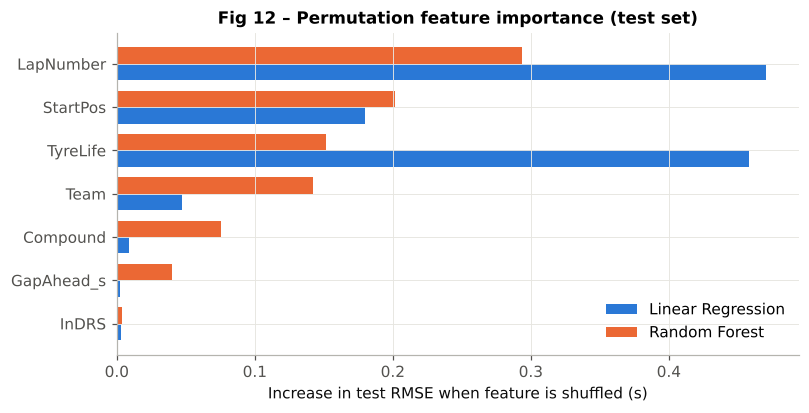

            Linear Regression  Random Forest
InDRS                  0.0029         0.0037
GapAhead_s             0.0026         0.0400
Compound               0.0088         0.0754
Team                   0.0476         0.1425
TyreLife               0.4578         0.1519
StartPos               0.1800         0.2014
LapNumber              0.4706         0.2939

Linear model coefficients in seconds (unscaled):
TyreLife             0.0683
TyreLife_x_Medium    0.0112
LapNumber           -0.0383
GapAhead_s          -0.0038
InDRS                0.0662
StartPos             0.0537
Compound_MEDIUM     -0.0747
dtype: float64


In [23]:
from sklearn.inspection import permutation_importance
imp = {}
for name, model in [("Linear Regression", final_lr), ("Random Forest", final_rf)]:
    pi = permutation_importance(model, X_test, y_test, n_repeats=30, random_state=SEED,
                                scoring="neg_root_mean_squared_error")
    imp[name] = pd.Series(pi.importances_mean, index=X_test.columns)
imp = pd.DataFrame(imp).sort_values("Random Forest")
fig, ax = plt.subplots(figsize=(8, 3.8))
yy = np.arange(len(imp)); h = 0.38
ax.barh(yy - h / 2, imp["Linear Regression"], h, color=LR_C, label="Linear Regression")
ax.barh(yy + h / 2, imp["Random Forest"], h, color=RF_C, label="Random Forest")
ax.set_yticks(yy); ax.set_yticklabels(imp.index)
ax.set_xlabel("Increase in test RMSE when feature is shuffled (s)")
ax.set_title("Fig 12 – Permutation feature importance (test set)"); ax.legend(loc="lower right")
fig.savefig(FIG / "fig12_importance.png"); plt.show()
print(imp.round(4))

# Interpretable LR coefficients (refit M2 on unscaled features so units are seconds)
Z = add_interactions(clean[FEATS_NUM + FEATS_CAT])
Zd = pd.get_dummies(Z, columns=FEATS_CAT, drop_first=True).astype(float)
lr_raw = LinearRegression().fit(Zd, y)
coef = pd.Series(lr_raw.coef_, index=Zd.columns)
print("\nLinear model coefficients in seconds (unscaled):")
print(coef[["TyreLife", "TyreLife_x_Medium", "LapNumber", "GapAhead_s", "InDRS", "StartPos", "Compound_MEDIUM"]].round(4))

**Interpretation (Fig 12).**
* **LR relies almost entirely on physics:** `LapNumber` (fuel, +0.47 s when shuffled) and `TyreLife` (+0.46 s).
* **RF spreads its attention:** `LapNumber` 0.29, `StartPos` 0.20, `TyreLife` 0.15, `Team` 0.14, `Compound` 0.08, `GapAhead_s` 0.04. It extracts more from Team and Compound through interactions (for example, a fast car on old Hards), which is where its extra accuracy comes from.
* `InDRS` is worth ≈0 for both, as Fig 6 predicted: at Monza, following within a second does not change lap time on average.

**Linear coefficients in seconds** (M2 refit on unscaled data). Each lap of tyre age costs **+0.068 s on the Hard** and **+0.080 s on the Medium** (0.068 + 0.011). Each race lap saves **−0.038 s** from fuel burn; at ≈2 kg per lap that is ≈0.02 s per kg. The Medium starts **0.075 s faster** but degrades faster, so it stops being the quicker tyre after about **0.0747 / 0.0112 ≈ 7 laps**. Each place further back costs +0.054 s, a proxy for car pace. These numbers are the kind of tyre model strategists use [5], and the forest cannot give them.

## 12. Critical evaluation – can the models forecast the end of the race?
A random split lets the model see laps 10 and 12 of a stint and predict lap 11, which is **interpolation**. Strategy needs **forecasting**: "how fast will we be in 10 laps if we don't stop?". Here every model is trained on laps 2–38 and tested on laps 39–51, which also means tyre ages beyond those seen in training. This mirrors the forecasting framing of Todd et al. [1].

In [24]:
# CRITICAL TEST: can the models forecast the END of the race? Train on laps 2-38, test on 39-51.
CUT = 38
tr_mask = clean["LapNumber"] <= CUT
Xf_tr, Xf_te, yf_tr, yf_te = X[tr_mask], X[~tr_mask], y[tr_mask], y[~tr_mask]
fwd = {}
fwd_models = {
    "Linear Regression": lr_pipeline(best_lr_name),
    "Random Forest": Pipeline([("pre", clone(rf_pre)), ("rf", RandomForestRegressor(n_estimators=N_TREES, random_state=SEED, n_jobs=-1, **best_rf_params))]),
}
fwd_pred = {}
for name, m in fwd_models.items():
    m.fit(Xf_tr, yf_tr); p = m.predict(Xf_te); fwd_pred[name] = p
    fwd[name] = {"Forward RMSE (s)": rmse(yf_te, p), "Forward MAE (s)": mean_absolute_error(yf_te, p),
                 "Forward R²": r2_score(yf_te, p)}
fwd_tbl = pd.DataFrame(fwd).round(4)
# How every linear variant behaves when it must extrapolate (CV only measured interpolation)
variant_tbl = pd.DataFrame({v: {"Random hold-out RMSE (s)": rmse(y_test, lr_pipeline(v).fit(X_train, y_train).predict(X_test)),
                                "Forecast laps 39-51 RMSE (s)": rmse(yf_te, lr_pipeline(v).fit(Xf_tr, yf_tr).predict(Xf_te))}
                            for v in lr_cv["Linear model"]}).T.round(4)
print(variant_tbl, "\n")
print(f"Train laps: {tr_mask.sum()} (laps 2-{CUT}) | Test laps: {(~tr_mask).sum()} (laps {CUT+1}-51)")
print("Max tyre life in training:", Xf_tr.groupby("Compound")["TyreLife"].max().to_dict(),
      "| in test:", Xf_te.groupby("Compound")["TyreLife"].max().to_dict())
out_of_range = (Xf_te["TyreLife"] > Xf_te["Compound"].map(Xf_tr.groupby("Compound")["TyreLife"].max())).mean()
print(f"Share of test laps with a tyre age never seen in training: {out_of_range*100:.1f}%")
fwd_tbl

                        Random hold-out RMSE (s)  Forecast laps 39-51 RMSE (s)
M1 linear main effects                    0.3806                        0.4445
M2 + TyreLife×Compound                    0.3777                        0.4493
M3 + TyreLife×Team                        0.3766                        0.4793
M4 polynomial (deg 2)                     0.3543                        0.5229 

Train laps: 650 (laps 2-38) | Test laps: 212 (laps 39-51)
Max tyre life in training: {'HARD': 29.0, 'MEDIUM': 22.0} | in test: {'HARD': 39.0, 'MEDIUM': 28.0}
Share of test laps with a tyre age never seen in training: 23.1%


,Linear Regression,Random Forest
Forward RMSE (s),0.4493,0.5281
Forward MAE (s),0.3388,0.4211
Forward R²,0.4230,0.2028


**Interpretation.** **23 % of the forecast laps have a tyre age never seen in training** (Hard up to 39 laps vs 29 in training; Medium 28 vs 22). Here the ranking **reverses**: Linear Regression RMSE **0.449 s** vs Random Forest **0.528 s** (+17.5 %), R² 0.42 vs 0.20 (**hypothesis 3 confirmed**). Within the linear family, the M4 polynomial that *won* cross-validation is now the worst (0.523 s) and the simplest M1 is the best (0.445 s). **Random-fold CV measured only interpolation**, so it rewarded flexibility that fails out of range, and the one-SE rule protected us. Both models score lower than on the random split, because the final laps also contain tyre management and battles that the features do not capture.

**Why this graph:** to see the mechanism behind the reversal for individual drivers: Sainz (3rd) and Norris (8th), both Medium → Hard one-stoppers.

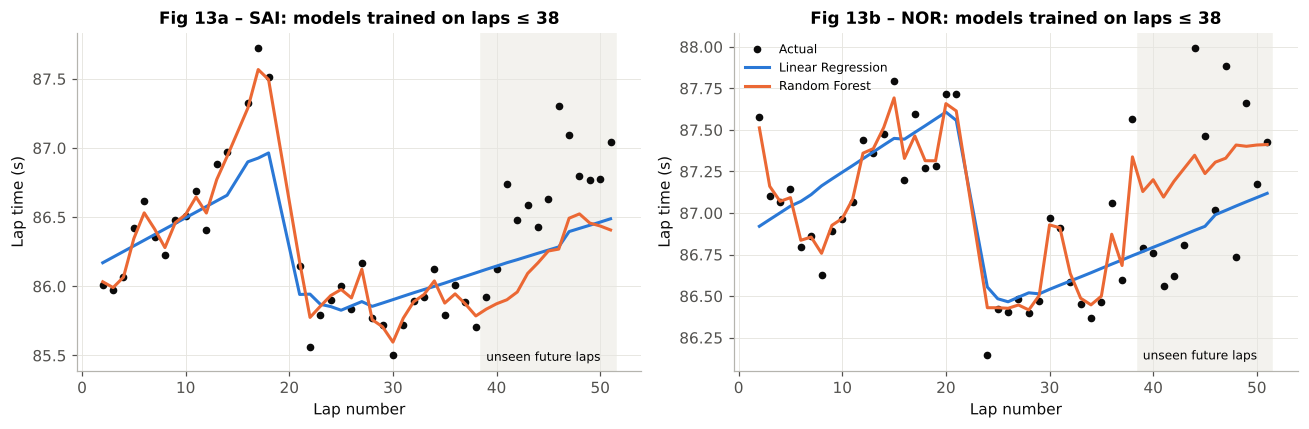

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=False)
for ax, drv in zip(axes, ["SAI", "NOR"]):
    g = clean[clean["Driver"] == drv].sort_values("LapNumber")
    mfull = {n: m for n, m in fwd_models.items()}
    ax.plot(g["LapNumber"], g["LapTime_s"], "o", color=INK, ms=4, label="Actual")
    for name, col in [("Linear Regression", LR_C), ("Random Forest", RF_C)]:
        ax.plot(g["LapNumber"], mfull[name].predict(g[FEATS_NUM + FEATS_CAT]), color=col, lw=2, label=name)
    ax.axvspan(CUT + 0.5, 51.5, color="#f3f2ee"); ax.text(CUT + 1, ax.get_ylim()[0] + 0.05, "unseen future laps", fontsize=8, va="bottom")
    ax.set_title(f"Fig 13{'a' if drv == 'SAI' else 'b'} – {drv}: models trained on laps ≤ {CUT}")
    ax.set_xlabel("Lap number"); ax.set_ylabel("Lap time (s)")
axes[1].legend(loc="upper left", fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "fig13_forward_forecast.png"); plt.show()

**Interpretation (Fig 13).** On the training laps (white area) the RF line zig-zags with the actual laps: it fits even small lap-to-lap noise, while the LR draws a smooth degradation trend. In the grey forecast area the **RF can only reuse lap times it has already seen**, so its forecast moves in steps and stops rising once tyre age passes the training maximum (Sainz, from lap ≈47). **The LR keeps rising along the learned degradation slope.** For individual drivers neither model is always closer (for Norris the RF happens to be nearer), but across all 212 forecast laps LR has the lower error. Both models miss Sainz's final laps, which were 0.5–1 s slower than either expects. That was the wheel-to-wheel fight for the podium, and no lap-level feature describes it.

## 13. Prediction with the chosen model
On the stated task (predicting lap times from tyre and race state) the **Random Forest is the better model**, so it is used for prediction. LR is shown alongside for contrast. Scenario: a **Ferrari running 4th, 2.5 s behind the car ahead, on lap 30**. How does its predicted lap time change with tyre age on each compound?

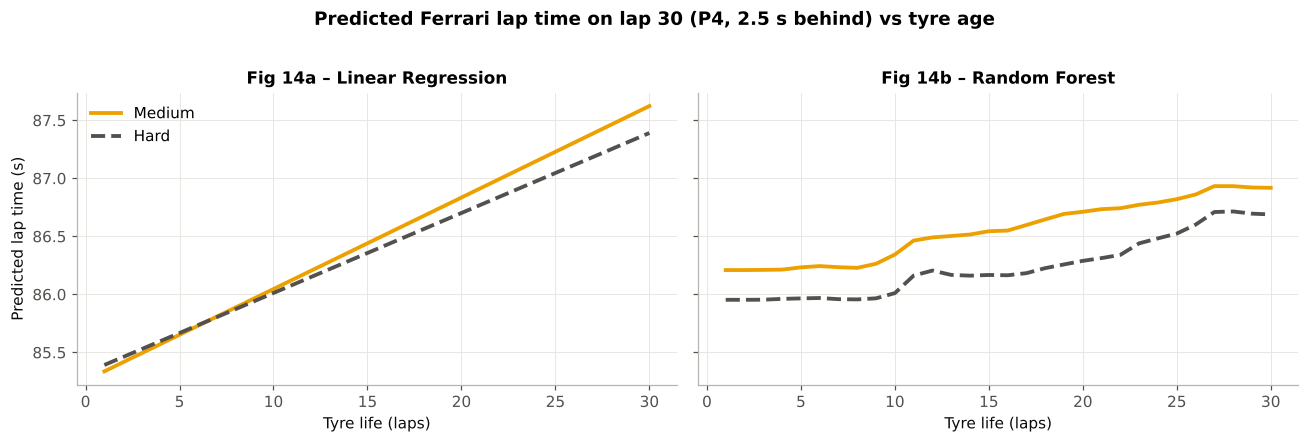

         LR prediction (s)         RF prediction (s)        
Compound              HARD  MEDIUM              HARD  MEDIUM
TyreLife                                                    
1                   85.392  85.337            85.953  86.209
5                   85.667  85.652            85.965  86.233
10                  86.012  86.046            86.011  86.343
15                  86.357  86.440            86.167  86.544
20                  86.701  86.834            86.289  86.712
25                  87.046  87.228            86.524  86.820
30                  87.390  87.623            86.689  86.918


,Driver,Team,LapNumber,Compound,TyreLife,GapAhead_s,Actual,RF,LR,RF error,LR error
513,OCO,Alpine,4.0,MEDIUM,4.0,0.912,87.582,87.510,87.543,-0.072,-0.039
787,SAR,Williams,35.0,HARD,24.0,9.745,87.233,87.205,87.181,-0.028,-0.052
931,ZHO,Alfa Romeo,25.0,HARD,17.0,0.922,87.028,87.309,87.533,0.281,0.505
554,PER,Red Bull Racing,6.0,MEDIUM,6.0,0.575,86.465,86.433,86.587,-0.032,0.122
111,BOT,Alfa Romeo,10.0,HARD,13.0,0.718,87.863,87.549,87.828,-0.314,-0.035
636,PIA,McLaren,37.0,HARD,19.0,0.697,86.806,86.832,86.815,0.026,0.009


In [26]:
# PREDICTION with the chosen model: a Ferrari running 4th, 2.5 s behind the car ahead, on lap 30
scenario = pd.DataFrame({
    "TyreLife": list(range(1, 31)) * 2,
    "LapNumber": 30, "GapAhead_s": 2.5, "StartPos": 4, "InDRS": 0,
    "Compound": ["MEDIUM"] * 30 + ["HARD"] * 30, "Team": "Ferrari",
})
scenario["RF prediction (s)"] = final_rf.predict(scenario[FEATS_NUM + FEATS_CAT])
scenario["LR prediction (s)"] = final_lr.predict(scenario[FEATS_NUM + FEATS_CAT])

fig, axes = plt.subplots(1, 2, figsize=(12, 3.9), sharey=True)
for ax, col_name, col, ttl in [(axes[0], "LR prediction (s)", LR_C, "a – Linear Regression"),
                               (axes[1], "RF prediction (s)", RF_C, "b – Random Forest")]:
    for comp, ls in [("MEDIUM", "-"), ("HARD", "--")]:
        s = scenario[scenario["Compound"] == comp]
        ax.plot(s["TyreLife"], s[col_name], ls, color=COMP_C[comp], lw=2.5, label=comp.title())
    ax.set_title(f"Fig 14{ttl}")
    ax.set_xlabel("Tyre life (laps)")
axes[0].set_ylabel("Predicted lap time (s)"); axes[0].legend()
fig.suptitle("Predicted Ferrari lap time on lap 30 (P4, 2.5 s behind) vs tyre age", fontweight="bold", y=1.02)
fig.tight_layout(); fig.savefig(FIG / "fig14_prediction_scenario.png"); plt.show()

piv = scenario.pivot_table(index="TyreLife", columns="Compound", values=["LR prediction (s)", "RF prediction (s)"])
print(piv.loc[[1, 5, 10, 15, 20, 25, 30]].round(3))

# Five real laps from the held-out test set, predicted by the Random Forest
show = X_test.assign(Driver=clean.loc[X_test.index, "Driver"], Actual=y_test,
                     RF=final_rf.predict(X_test), LR=final_lr.predict(X_test)).sample(6, random_state=1)
show["RF error"] = show["RF"] - show["Actual"]; show["LR error"] = show["LR"] - show["Actual"]
show[["Driver", "Team", "LapNumber", "Compound", "TyreLife", "GapAhead_s", "Actual", "RF", "LR", "RF error", "LR error"]].round(3)

**Interpretation (Fig 14).**
* **Linear Regression (a):** straight lines, as the model structure dictates. The Medium is marginally faster for the first ~7 laps, then the Hard is faster, and by 30 laps the Hard is 0.23 s quicker. The model will also predict tyre ages it has never seen, which is useful for forecasting but potentially overconfident.
* **Random Forest (b):** a stepped curve, flat for the first ~9 laps and then rising. It predicts the **Hard faster at every age by ≈0.2–0.35 s**. The flat start and the steps are the visual signature of tree leaves.
* **Strategic reading:** both models agree that the Hard was the better race tyre at Monza 2023, consistent with most drivers running Medium → Hard. The table of six real test laps shows typical RF errors of a few hundredths to ≈0.3 s.

## 14. Comparison with the reference study
Todd et al. [1] predict a different quantity (tyre energy from 10 Hz Mercedes telemetry), so raw RMSE values are not comparable. The **relative change in RMSE between the tree ensemble and the linear model** is comparable, and that is what we compare.

                                             Study  Linear RMSE  Tree-ensemble RMSE    Tree model  Tree vs linear (% RMSE change)
Todd et al. 2025 (tyre energy, Mercedes telemetry)        7.916               4.785       XGBoost                         -39.553
                    This project – random hold-out        0.378               0.301 Random Forest                         -20.229
                This project – forecast laps 39-51        0.449               0.528 Random Forest                          17.537


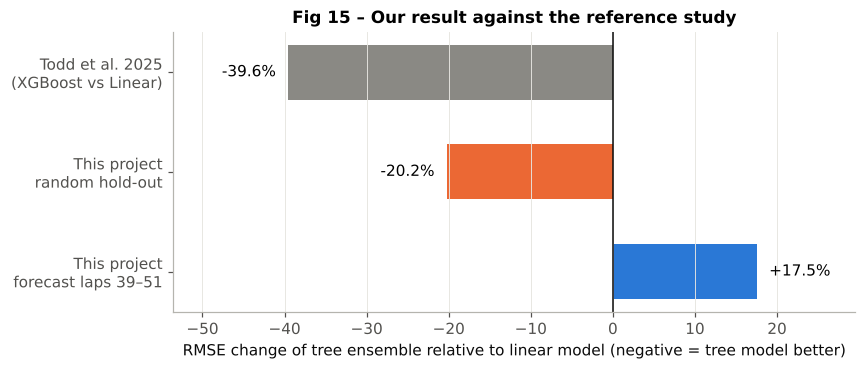

In [27]:
bench = pd.DataFrame({
    "Study": ["Todd et al. 2025 (tyre energy, Mercedes telemetry)", "This project – random hold-out", "This project – forecast laps 39-51"],
    "Linear RMSE": [7.916, results["Linear Regression"]["Test RMSE (s)"], fwd["Linear Regression"]["Forward RMSE (s)"]],
    "Tree-ensemble RMSE": [4.785, results["Random Forest"]["Test RMSE (s)"], fwd["Random Forest"]["Forward RMSE (s)"]],
    "Tree model": ["XGBoost", "Random Forest", "Random Forest"],
})
bench["Tree vs linear (% RMSE change)"] = (bench["Tree-ensemble RMSE"] / bench["Linear RMSE"] - 1) * 100
print(bench.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 3.3))
vals = bench["Tree vs linear (% RMSE change)"].values
labels = ["Todd et al. 2025\n(XGBoost vs Linear)", "This project\nrandom hold-out", "This project\nforecast laps 39–51"]
cols = [MUTED, RF_C, LR_C]
ax.barh(labels, vals, color=cols, height=0.55); ax.grid(axis="y", visible=False)
for i, v in enumerate(vals):
    ax.text(v + (1.5 if v > 0 else -1.5), i, f"{v:+.1f}%", va="center", ha="left" if v > 0 else "right", fontsize=10)
ax.axvline(0, color=INK, lw=1); ax.invert_yaxis()
ax.set_xlim(min(vals) - 14, max(15, max(vals) + 12))
ax.set_xlabel("RMSE change of tree ensemble relative to linear model (negative = tree model better)")
ax.set_title("Fig 15 – Our result against the reference study")
fig.savefig(FIG / "fig15_benchmark.png"); plt.show()

**Interpretation (Fig 15).** On the random hold-out we reproduce the *direction* of Todd et al.'s finding: the tree ensemble beats linear regression, by **20 %** here vs **40 %** for XGBoost in [1]. Our gain is smaller because (i) we have 7 lap-level features and 862 laps, vs dozens of high-frequency telemetry channels over 33 events; (ii) XGBoost's gradient boosting is usually stronger than bagging; and (iii) lap time at Monza is close to additive (Figs 3–4), so a linear model already captures most of it. When the task requires **extrapolation**, the result **reverses (+17.5 %)**. This is a limitation of tree models that [1] does not test, because its event-level split still spans similar operating conditions. Pereira et al. [4] also keep a linear model as the backbone of their lap-time predictor.

## 15. Extension – a residual hybrid (beyond the two required methods)
Inspired by Pereira et al. [4]: let Linear Regression capture the extrapolatable physics (fuel and tyre trends), then train a Random Forest on **what LR gets wrong** (its residuals). Prediction = LR + RF(residual).

In [28]:
# EXTENSION inspired by Pereira et al. (2026): linear model for the trend + Random Forest on its residuals
class ResidualHybrid:
    def __init__(self): self.lr = lr_pipeline(best_lr_name); self.rf = Pipeline([("pre", clone(rf_pre)), ("rf",
        RandomForestRegressor(n_estimators=N_TREES, random_state=SEED, n_jobs=-1, **best_rf_params))])
    def fit(self, X, y):
        self.lr.fit(X, y); self.rf.fit(X, y - self.lr.predict(X)); return self
    def predict(self, X): return self.lr.predict(X) + self.rf.predict(X)
hyb_h = ResidualHybrid().fit(X_train, y_train)
hyb_f = ResidualHybrid().fit(Xf_tr, yf_tr)
hybrid_tbl = pd.DataFrame({
    "Random hold-out RMSE (s)": [results["Linear Regression"]["Test RMSE (s)"], results["Random Forest"]["Test RMSE (s)"], rmse(y_test, hyb_h.predict(X_test))],
    "Forecast laps 39-51 RMSE (s)": [fwd["Linear Regression"]["Forward RMSE (s)"], fwd["Random Forest"]["Forward RMSE (s)"], rmse(yf_te, hyb_f.predict(Xf_te))],
}, index=["Linear Regression", "Random Forest", "Hybrid LR + RF-on-residuals"]).round(4)
hybrid_tbl

,Random hold-out RMSE (s),Forecast laps 39-51 RMSE (s)
Linear Regression,0.3777,0.4493
Random Forest,0.3013,0.5281
Hybrid LR + RF-on-residuals,0.2909,0.4472


**Interpretation.** The hybrid is **best on both tests**: 0.291 s on the random hold-out (better than the RF's 0.301 s) and 0.447 s on the forecast (matching LR's 0.449 s). It keeps the RF's interaction modelling without losing the LR's ability to extrapolate, which supports the residual-learning idea of [4].

## 16. Conclusions
| | Linear Regression (M2) | Random Forest |
|---|---|---|
| CV validation RMSE | 0.379 s | 0.327 s |
| **Test RMSE (random hold-out)** | 0.378 s | **0.301 s** |
| Test MAE / R² | 0.284 s / 0.715 | **0.218 s / 0.819** |
| **Forecast RMSE (laps 39–51)** | **0.449 s** | 0.528 s |
| Fit time | **0.009 s** | 0.62 s |
| Interpretability | **seconds per lap of tyre age / fuel** | permutation importance only |

**Which is better, and why?**
* For **predicting lap times within the range of the data**, the **Random Forest is significantly better** (−20 % RMSE; Wilcoxon p < 10⁻⁶). It models interactions between car, compound and race phase that the additive linear model cannot.
* For **forecasting future laps**, which is what a strategist actually needs, **Linear Regression is better** (−15 % RMSE vs RF). Its additive structure matches the physics [5] and it extrapolates the degradation trend, while trees flat-line beyond the largest tyre age seen in training.
* The two methods are complementary; the residual hybrid gives the best of both.

**Lessons learned**
1. **Leakage control matters more than the algorithm.** Sector times or speed traps would give near-perfect but useless models.
2. **The validation scheme must match the use case.** Random-fold CV chose the polynomial LR, which then performed worst at forecasting.
3. A small, well-chosen feature set that mirrors domain knowledge (fuel, tyre age, car) explains ~72–82 % of lap-time variance.
4. Expected effects should be tested, not assumed: the DRS/dirty-air effect did not appear at Monza.

**Limitations:** one race and one circuit (Monza, low downforce, two compounds); laps from the same driver are correlated; no weather or telemetry; lapped traffic is not modelled.

**Future work**
* Extend to every dry race of 2022–2024 (the `download_more_races.py` script in this folder) and test on **unseen circuits**, as in [1].
* Add per-lap telemetry summaries from `get_car_data()` (mean throttle, % full throttle, braking events) and track temperature from `weather_data`.
* Use group-aware validation (`GroupKFold` by driver or race) and time-series CV.
* Compare against gradient boosting (XGBoost), the best model in [1].

## References
[1] J. Todd, J. Jiang, A. Russo, S. Winkler, S. Sale, J. McMillan, A. Rago, "Explainable Time Series Prediction of Tyre Energy in Formula One Race Strategy," *Proc. 40th ACM/SIGAPP Symposium on Applied Computing (SAC '25)*, 2025. doi:10.1145/3672608.3707765
[2] Nova School of Business and Economics, "From Data to Podium: Analytical Approaches to Understanding and Predicting Driver & Strategic Decisions in Formula 1," Master's Work Project (Business Analytics), 2023. https://run.unl.pt/bitstream/10362/176923/1/F1_Pitstop_Strategy_Individual_Version.pdf
[3] J. G. R. de Faria, F. G. Ferreira, "Podium and Influence: A Network Analysis of the Most Important Formula One Drivers," *Proc. 13th BraSNAM*, SBC, pp. 144–157, 2024. doi:10.5753/brasnam.2024.3054
[4] M. P. O. Pereira, C. H. G. Ferreira, A. M. de Sousa, "Residual Hybrid Learning for Data-Limited Formula 1 Lap Time Prediction Across Multiple Circuits," *Proc. 14th KDMiLe*, SBC, pp. 201–208, 2026. doi:10.5753/kdmile.2026.32096
[5] A. Heilmeier, M. Graf, J. Betz, M. Lienkamp, "Application of Monte Carlo Methods to Consider Probabilistic Effects in a Race Simulation for Circuit Motorsport," *Applied Sciences*, 10(12):4229, 2020. doi:10.3390/app10124229
[6] L. Breiman, "Random Forests," *Machine Learning*, 45:5–32, 2001.
[7] C. M. Bishop, *Pattern Recognition and Machine Learning*, Springer, 2006 (Ch. 3, linear models for regression).
[8] T. Hastie, R. Tibshirani, J. Friedman, *The Elements of Statistical Learning*, 2nd ed., Springer, 2009 (§7.10, one-standard-error rule).
[9] C. Nadeau, Y. Bengio, "Inference for the Generalization Error," *Machine Learning*, 52:239–281, 2003.
[10] P. Schaefer et al., *FastF1* Python package, v3.9. https://docs.fastf1.dev
